/tmp/ipython-input-3-288508334.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
[*********************100%***********************]  9 of 9 completed
/tmp/ipython-input-3-288508334.py:54: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill').fillna(method='bfill')
/tmp/ipython-input-3-288508334.py:99: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  portfolio['Returns'] = portfolio['Total_Value'].pct_change().fillna(0)


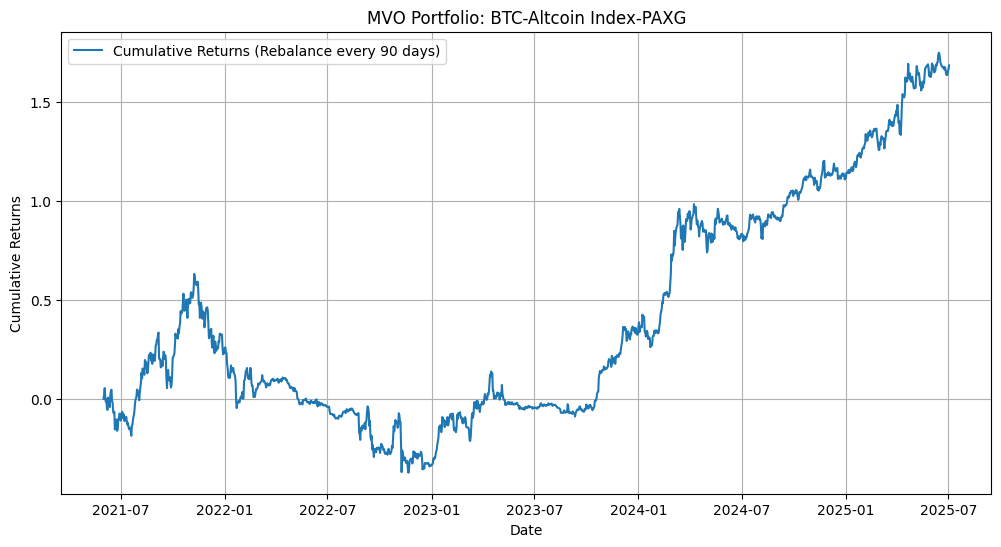

MVO Portfolio Performance Metrics (Rebalance every 90 days):
Annualized Return: 22.25%
Sharpe Ratio: 0.67
Max Drawdown: 61.53%


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Define tickers, time period, and parameters
altcoins = ['XRP-USD', 'SOL-USD','ETH-USD','BNB-USD','TON-USD', 'ADA-USD','SUI-USD']
btc_ticker = 'BTC-USD'
paxg_ticker = 'PAXG-USD'
tickers = [btc_ticker, paxg_ticker] + altcoins
start_date = '2021-06-01'
end_date = '2025-07-03'
rebalance_days = 90  # Number of days between rebalancing (adjustable)
lookback_period = 252  # Lookback period for estimating returns and covariance
initial_investment = 10000  # Starting capital in USD


# Function to calculate portfolio return and volatility
def portfolio_performance(weights, returns, cov_matrix, annual_factor=252):
    portfolio_return = np.sum(returns.mean() * weights) * annual_factor
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * annual_factor, weights)))
    return portfolio_return, portfolio_volatility

# Function to calculate negative Sharpe ratio for minimization
def neg_sharpe_ratio(weights, returns, cov_matrix, risk_free_rate=0):
    port_return, port_volatility = portfolio_performance(weights, returns, cov_matrix)
    return - (port_return - risk_free_rate) / port_volatility

# Function to optimize portfolio weights
def optimize_portfolio(returns):
    n_assets = returns.shape[1]
    cov_matrix = returns.cov()
    init_guess = np.array([1/n_assets] * n_assets)  # Equal weights as initial guess
    bounds = [(0, 1) for _ in range(n_assets)]  # Long-only
    constraints = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}  # Sum of weights = 1
    result = minimize(neg_sharpe_ratio, init_guess, args=(returns, cov_matrix),
                     method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x if result.success else init_guess

# Fetch historical data (Close prices)
try:
    data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
except Exception as e:
    print(f"Error fetching data: {e}")
    exit()

# Check for sufficient data
if data.empty or data.isna().all().all():
    print("No data retrieved. Check tickers or internet connection.")
    exit()

# Handle missing data
data = data.fillna(method='ffill').fillna(method='bfill')

# Create altcoin index (equal-weighted average of prices)
altcoin_index = data[altcoins].mean(axis=1)

# Combine BTC, altcoin index, and PAXG into a single DataFrame
portfolio_data = pd.DataFrame({
    'BTC': data[btc_ticker],
    'Altcoin_Index': altcoin_index,
    'PAXG': data[paxg_ticker]
})

# Calculate daily returns
returns = portfolio_data.pct_change().fillna(0)

# Initialize portfolio
portfolio = pd.DataFrame(index=portfolio_data.index, columns=['BTC_Value', 'Index_Value', 'PAXG_Value', 'Total_Value', 'BTC_Weight', 'Index_Weight', 'PAXG_Weight'])
portfolio.iloc[0] = [initial_investment * 0.5, initial_investment * 0.25, initial_investment * 0.25, initial_investment, 0.5, 0.25, 0.25]

# Simulate portfolio with MVO rebalancing
for i in range(1, len(portfolio)):
    # Carry forward previous day's values
    prev_btc_value = portfolio['BTC_Value'].iloc[i-1]
    prev_index_value = portfolio['Index_Value'].iloc[i-1]
    prev_paxg_value = portfolio['PAXG_Value'].iloc[i-1]

    btc_value = prev_btc_value * (1 + returns['BTC'].iloc[i])
    index_value = prev_index_value * (1 + returns['Altcoin_Index'].iloc[i])
    paxg_value = prev_paxg_value * (1 + returns['PAXG'].iloc[i])

    # Check if rebalancing is needed
    if i % rebalance_days == 0 and i >= lookback_period:
        # Use lookback period returns for optimization
        lookback_returns = returns.iloc[i-lookback_period:i]
        weights = optimize_portfolio(lookback_returns)
        total_value = btc_value + index_value + paxg_value
        btc_value = total_value * weights[0]
        index_value = total_value * weights[1]
        paxg_value = total_value * weights[2]
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, total_value, weights[0], weights[1], weights[2]]
    else:
        total_value = btc_value + index_value + paxg_value
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, total_value, btc_value/total_value, index_value/total_value, paxg_value/total_value]

# Calculate portfolio returns
portfolio['Returns'] = portfolio['Total_Value'].pct_change().fillna(0)
cumulative_returns = (1 + portfolio['Returns']).cumprod() - 1

# Calculate maximum drawdown (corrected formula)
portfolio_value = portfolio['Total_Value']
running_max = portfolio_value.cummax()
drawdowns = (running_max - portfolio_value) / running_max * 100
max_drawdown = drawdowns.max() if not drawdowns.empty else 0

# Performance metrics
annualized_return = portfolio['Returns'].mean() * 252 * 100  # Annualized return (%)
sharpe_ratio = portfolio['Returns'].mean() / portfolio['Returns'].std() * np.sqrt(252) if portfolio['Returns'].std() != 0 else 0

# Save portfolio data
portfolio.to_csv('btc_altcoin_paxg_mvo_portfolio.csv')

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cumulative_returns.index, cumulative_returns, label=f'Cumulative Returns (Rebalance every {rebalance_days} days)')

plt.title('MVО Portfolio: BTC-Altcoin Index-PAXG')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.legend()
plt.grid()
plt.savefig('btc_altcoin_paxg_mvo_portfolio_plot.png')
plt.show()


# Print performance metrics
print(f"MVO Portfolio Performance Metrics (Rebalance every {rebalance_days} days):")
print(f"Annualized Return: {annualized_return:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Max Drawdown: {max_drawdown:.2f}%")

/tmp/ipython-input-4-3401328598.py:50: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
[*********************100%***********************]  9 of 9 completed
/tmp/ipython-input-4-3401328598.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill').fillna(method='bfill')


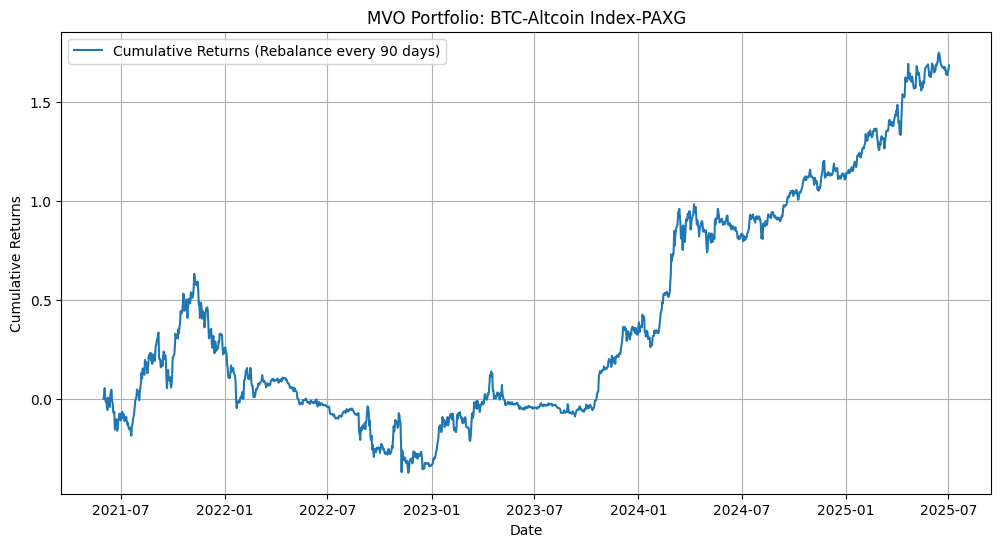

MVO Portfolio Performance Metrics (Rebalance every 90 days):
Annualized Return: 22.25%
Sharpe Ratio: 0.67
Max Drawdown: 61.53%
Average Beta (vs BTC-USD): 0.53
Average Beta (vs Equal-Weight Portfolio): 0.57


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Define tickers, time period, and parameters
altcoins = ['XRP-USD', 'SOL-USD', 'ETH-USD', 'BNB-USD', 'TON-USD', 'ADA-USD', 'SUI-USD']

btc_ticker = 'BTC-USD'
paxg_ticker = 'PAXG-USD'
tickers = [btc_ticker, paxg_ticker] + altcoins
start_date = '2021-06-01'
end_date = '2025-07-03'
rebalance_days = 90  # Number of days between rebalancing
lookback_period = 252  # Lookback period for estimating returns, covariance, and beta
initial_investment = 10000  # Starting capital in USD

# Function to calculate portfolio return and volatility
def portfolio_performance(weights, returns, cov_matrix, annual_factor=252):
    portfolio_return = np.sum(returns.mean() * weights) * annual_factor
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * annual_factor, weights)))
    return portfolio_return, portfolio_volatility

# Function to calculate negative Sharpe ratio for minimization
def neg_sharpe_ratio(weights, returns, cov_matrix, risk_free_rate=0):
    port_return, port_volatility = portfolio_performance(weights, returns, cov_matrix)
    return - (port_return - risk_free_rate) / port_volatility

# Function to optimize portfolio weights
def optimize_portfolio(returns):
    n_assets = returns.shape[1]
    cov_matrix = returns.cov()
    init_guess = np.array([1/n_assets] * n_assets)  # Equal weights as initial guess
    bounds = [(0, 1) for _ in range(n_assets)]  # Long-only
    constraints = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}  # Sum of weights = 1
    result = minimize(neg_sharpe_ratio, init_guess, args=(returns, cov_matrix),
                     method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x if result.success else init_guess

# Function to calculate beta
def calculate_beta(portfolio_returns, benchmark_returns, lookback_period):
    cov_matrix = pd.concat([portfolio_returns, benchmark_returns], axis=1).cov()
    covariance = cov_matrix.iloc[0, 1]
    benchmark_variance = benchmark_returns.var()
    return covariance / benchmark_variance if benchmark_variance != 0 else np.nan

# Fetch historical data (Close prices)
try:
    data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
except Exception as e:
    print(f"Error fetching data: {e}")
    exit()

# Check for sufficient data
if data.empty or data.isna().all().all():
    print("No data retrieved. Check tickers or internet connection.")
    exit()

# Handle missing data
data = data.fillna(method='ffill').fillna(method='bfill')

# Create altcoin index (equal-weighted average of prices)
altcoin_index = data[altcoins].mean(axis=1)

# Create equal-weight portfolio (benchmark)
equal_weight_portfolio = data[altcoins + [btc_ticker, paxg_ticker]].mean(axis=1)

# Combine BTC, altcoin index, and PAXG into a single DataFrame
portfolio_data = pd.DataFrame({
    'BTC': data[btc_ticker],
    'Altcoin_Index': altcoin_index,
    'PAXG': data[paxg_ticker]
})

# Calculate daily returns
returns = portfolio_data.pct_change().fillna(0)
btc_returns = data[btc_ticker].pct_change().fillna(0)
equal_weight_returns = equal_weight_portfolio.pct_change().fillna(0)

# Initialize portfolio
portfolio = pd.DataFrame(index=portfolio_data.index, columns=['BTC_Value', 'Index_Value', 'PAXG_Value', 'Total_Value', 'BTC_Weight', 'Index_Weight', 'PAXG_Weight', 'Returns', 'Beta_BTC', 'Beta_Equal_Weight'])
portfolio.iloc[0] = [initial_investment * 0.5, initial_investment * 0.25, initial_investment * 0.25, initial_investment, 0.5, 0.25, 0.25, 0.0, np.nan, np.nan]

# Simulate portfolio with MVO rebalancing and calculate betas
for i in range(1, len(portfolio)):
    # Carry forward previous day's values
    prev_btc_value = portfolio['BTC_Value'].iloc[i-1]
    prev_index_value = portfolio['Index_Value'].iloc[i-1]
    prev_paxg_value = portfolio['PAXG_Value'].iloc[i-1]
    prev_total_value = portfolio['Total_Value'].iloc[i-1]

    btc_value = prev_btc_value * (1 + returns['BTC'].iloc[i])
    index_value = prev_index_value * (1 + returns['Altcoin_Index'].iloc[i])
    paxg_value = prev_paxg_value * (1 + returns['PAXG'].iloc[i])

    total_value = btc_value + index_value + paxg_value
    portfolio_return = (total_value / prev_total_value) - 1 if prev_total_value != 0 else 0.0

    # Calculate beta if sufficient data is available
    beta_btc = np.nan
    beta_equal_weight = np.nan
    if i >= lookback_period:
        lookback_portfolio_returns = portfolio['Returns'].iloc[max(0, i-lookback_period):i]
        lookback_btc_returns = btc_returns.iloc[max(0, i-lookback_period):i]
        lookback_equal_weight_returns = equal_weight_returns.iloc[max(0, i-lookback_period):i]
        beta_btc = calculate_beta(lookback_portfolio_returns, lookback_btc_returns, lookback_period)
        beta_equal_weight = calculate_beta(lookback_portfolio_returns, lookback_equal_weight_returns, lookback_period)

    # Check if rebalancing is needed
    if i % rebalance_days == 0 and i >= lookback_period:
        lookback_returns = returns.iloc[i-lookback_period:i]
        weights = optimize_portfolio(lookback_returns)
        btc_value = total_value * weights[0]
        index_value = total_value * weights[1]
        paxg_value = total_value * weights[2]
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, total_value, weights[0], weights[1], weights[2], portfolio_return, beta_btc, beta_equal_weight]
    else:
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, total_value, btc_value/total_value, index_value/total_value, paxg_value/total_value, portfolio_return, beta_btc, beta_equal_weight]

# Calculate cumulative returns
cumulative_returns = (1 + portfolio['Returns']).cumprod() - 1

# Calculate maximum drawdown
portfolio_value = portfolio['Total_Value']
running_max = portfolio_value.cummax()
drawdowns = (running_max - portfolio_value) / running_max * 100
max_drawdown = drawdowns.max() if not drawdowns.empty else 0

# Performance metrics
annualized_return = portfolio['Returns'].mean() * 252 * 100
sharpe_ratio = portfolio['Returns'].mean() / portfolio['Returns'].std() * np.sqrt(252) if portfolio['Returns'].std() != 0 else 0
avg_beta_btc = portfolio['Beta_BTC'].mean()
avg_beta_equal_weight = portfolio['Beta_Equal_Weight'].mean()

# Save portfolio data
portfolio.to_csv('btc_altcoin_paxg_mvo_portfolio.csv')

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cumulative_returns.index, cumulative_returns, label=f'Cumulative Returns (Rebalance every {rebalance_days} days)')
plt.title('MVO Portfolio: BTC-Altcoin Index-PAXG')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.legend()
plt.grid()
plt.savefig('btc_altcoin_paxg_mvo_portfolio_plot.png')
plt.show()

# Print performance metrics
print(f"MVO Portfolio Performance Metrics (Rebalance every {rebalance_days} days):")
print(f"Annualized Return: {annualized_return:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Max Drawdown: {max_drawdown:.2f}%")
print(f"Average Beta (vs BTC-USD): {avg_beta_btc:.2f}")
print(f"Average Beta (vs Equal-Weight Portfolio): {avg_beta_equal_weight:.2f}")

/tmp/ipython-input-4107546018.py:50: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
[*********************100%***********************]  4 of 4 completed
/tmp/ipython-input-4107546018.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill').fillna(method='bfill')


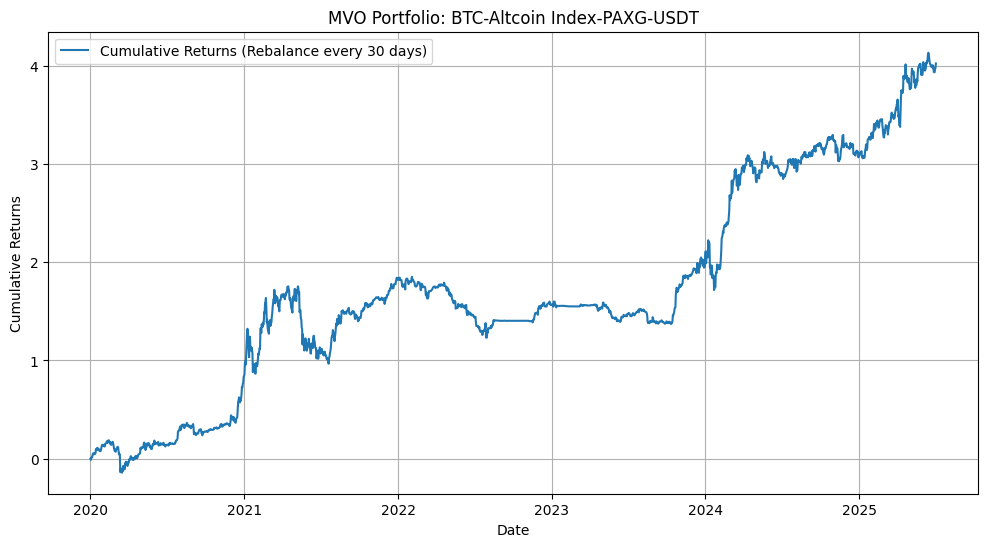

MVO Portfolio Performance Metrics (Rebalance every 30
Annualized Return: 22.56%
Sharpe Ratio: 1.05
Max Drawdown: 28.59%
Average Beta (vs BTC-USD): 0.25
Average Beta (vs Equal-Weight Portfolio): 0.27


In [10]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Define tickers, time period, and parameters
altcoins = ['PG']
btc_ticker = 'BTC-USD'
paxg_ticker = 'PAXG-USD'
usdt_ticker = 'USDT-USD'
tickers = [btc_ticker, paxg_ticker, usdt_ticker] + altcoins
start_date = '2020-01-01'
end_date = '2025-07-03'
rebalance_days = 30  # Number of days between rebalancing
lookback_period = 252  # Lookback period for estimating returns, covariance, and beta
initial_investment = 10000  # Starting capital in USD

# Function to calculate portfolio return and volatility
def portfolio_performance(weights, returns, cov_matrix, annual_factor=252):
    portfolio_return = np.sum(returns.mean() * weights) * annual_factor
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * annual_factor, weights)))
    return portfolio_return, portfolio_volatility

# Function to calculate negative Sharpe ratio for minimization
def neg_sharpe_ratio(weights, returns, cov_matrix, risk_free_rate=0):
    port_return, port_volatility = portfolio_performance(weights, returns, cov_matrix)
    return - (port_return - risk_free_rate) / port_volatility

# Function to optimize portfolio weights
def optimize_portfolio(returns):
    n_assets = returns.shape[1]
    cov_matrix = returns.cov()
    init_guess = np.array([1/n_assets] * n_assets)  # Equal weights as initial guess
    bounds = [(0, 1) for _ in range(n_assets)]  # Long-only
    constraints = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}  # Sum of weights = 1
    result = minimize(neg_sharpe_ratio, init_guess, args=(returns, cov_matrix),
                     method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x if result.success else init_guess

# Function to calculate beta
def calculate_beta(portfolio_returns, benchmark_returns, lookback_period):
    cov_matrix = pd.concat([portfolio_returns, benchmark_returns], axis=1).cov()
    covariance = cov_matrix.iloc[0, 1]
    benchmark_variance = benchmark_returns.var()
    return covariance / benchmark_variance if benchmark_variance != 0 else np.nan

# Fetch historical data (Close prices)
try:
    data = yf.download(tickers, start=start_date, end=end_date, interval='1d')['Close']
except Exception as e:
    print(f"Error fetching data: {e}")
    exit()

# Check for sufficient data
if data.empty or data.isna().all().all():
    print("No data retrieved. Check tickers or internet connection.")
    exit()

# Handle missing data
data = data.fillna(method='ffill').fillna(method='bfill')

# Create altcoin index (equal-weighted average of prices)
altcoin_index = data[altcoins].mean(axis=1)

# Create equal-weight portfolio (benchmark)
equal_weight_portfolio = data[altcoins + [btc_ticker, paxg_ticker, usdt_ticker]].mean(axis=1)

# Combine BTC, altcoin index, PAXG, and USDT into a single DataFrame
portfolio_data = pd.DataFrame({
    'BTC': data[btc_ticker],
    'Altcoin_Index': altcoin_index,
    'PAXG': data[paxg_ticker],
    'USDT': data[usdt_ticker]
})

# Calculate daily returns
returns = portfolio_data.pct_change().fillna(0)
btc_returns = data[btc_ticker].pct_change().fillna(0)
equal_weight_returns = equal_weight_portfolio.pct_change().fillna(0)

# Initialize portfolio
portfolio = pd.DataFrame(index=portfolio_data.index, columns=[
    'BTC_Value', 'Index_Value', 'PAXG_Value', 'USDT_Value', 'Total_Value',
    'BTC_Weight', 'Index_Weight', 'PAXG_Weight', 'USDT_Weight', 'Returns',
    'Beta_BTC', 'Beta_Equal_Weight'
])
portfolio.iloc[0] = [initial_investment * 0.4, initial_investment * 0.2, initial_investment * 0.2, initial_investment * 0.2,
                     initial_investment, 0.4, 0.2, 0.2, 0.2, 0.0, np.nan, np.nan]

# Simulate portfolio with MVO rebalancing and calculate betas
for i in range(1, len(portfolio)):
    # Carry forward previous day's values
    prev_btc_value = portfolio['BTC_Value'].iloc[i-1]
    prev_index_value = portfolio['Index_Value'].iloc[i-1]
    prev_paxg_value = portfolio['PAXG_Value'].iloc[i-1]
    prev_usdt_value = portfolio['USDT_Value'].iloc[i-1]
    prev_total_value = portfolio['Total_Value'].iloc[i-1]

    btc_value = prev_btc_value * (1 + returns['BTC'].iloc[i])
    index_value = prev_index_value * (1 + returns['Altcoin_Index'].iloc[i])
    paxg_value = prev_paxg_value * (1 + returns['PAXG'].iloc[i])
    usdt_value = prev_usdt_value * (1 + returns['USDT'].iloc[i])

    total_value = btc_value + index_value + paxg_value + usdt_value
    portfolio_return = (total_value / prev_total_value) - 1 if prev_total_value != 0 else 0.0

    # Calculate beta if sufficient data is available
    beta_btc = np.nan
    beta_equal_weight = np.nan
    if i >= lookback_period:
        lookback_portfolio_returns = portfolio['Returns'].iloc[max(0, i-lookback_period):i]
        lookback_btc_returns = btc_returns.iloc[max(0, i-lookback_period):i]
        lookback_equal_weight_returns = equal_weight_returns.iloc[max(0, i-lookback_period):i]
        beta_btc = calculate_beta(lookback_portfolio_returns, lookback_btc_returns, lookback_period)
        beta_equal_weight = calculate_beta(lookback_portfolio_returns, lookback_equal_weight_returns, lookback_period)

    # Check if rebalancing is needed
    if i % rebalance_days == 0 and i >= lookback_period:
        lookback_returns = returns.iloc[i-lookback_period:i]
        weights = optimize_portfolio(lookback_returns)
        btc_value = total_value * weights[0]
        index_value = total_value * weights[1]
        paxg_value = total_value * weights[2]
        usdt_value = total_value * weights[3]
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, usdt_value, total_value,
                             weights[0], weights[1], weights[2], weights[3], portfolio_return,
                             beta_btc, beta_equal_weight]
    else:
        portfolio.iloc[i] = [btc_value, index_value, paxg_value, usdt_value, total_value,
                             btc_value/total_value, index_value/total_value, paxg_value/total_value, usdt_value/total_value,
                             portfolio_return, beta_btc, beta_equal_weight]

# Calculate cumulative returns
cumulative_returns = (1 + portfolio['Returns']).cumprod() - 1

# Calculate maximum drawdown
portfolio_value = portfolio['Total_Value']
running_max = portfolio_value.cummax()
drawdowns = (running_max - portfolio_value) / running_max * 100
max_drawdown = drawdowns.max() if not drawdowns.empty else 0

# Performance metrics
annualized_return = portfolio['Returns'].mean() * 252 * 100
sharpe_ratio = portfolio['Returns'].mean() / portfolio['Returns'].std() * np.sqrt(252) if portfolio['Returns'].std() != 0 else 0
avg_beta_btc = portfolio['Beta_BTC'].mean()
avg_beta_equal_weight = portfolio['Beta_Equal_Weight'].mean()

# Save portfolio data
portfolio.to_csv('btc_altcoin_paxg_usdt_mvo_portfolio.csv')

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cumulative_returns.index, cumulative_returns, label=f'Cumulative Returns (Rebalance every {rebalance_days} days)')
plt.title('MVO Portfolio: BTC-Altcoin Index-PAXG-USDT')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.legend()
plt.grid()
plt.savefig('btc_altcoin_paxg_usdt_mvo_portfolio_plot.png')
plt.show()

# Print performance metrics
print(f"MVO Portfolio Performance Metrics (Rebalance every {rebalance_days}")
print(f"Annualized Return: {annualized_return:.2f}%")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Max Drawdown: {max_drawdown:.2f}%")
print(f"Average Beta (vs BTC-USD): {avg_beta_btc:.2f}")
print(f"Average Beta (vs Equal-Weight Portfolio): {avg_beta_equal_weight:.2f}")